# **📶Telecom Customer Churn Analysis + Business Recommendations📲🛜**

# **📦Importing libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
import plotly.io as pio
pio.renderers.default = "iframe"
import plotly.express as px
import os

# **📂Loading Dataset**

In [2]:
os.makedirs("/kaggle/working/plots/",exist_ok=True)
# Reading the CSV file as a dataframe
telecom_customers_churned = pd.read_csv("/kaggle/input/datasets/alipakzad/telecom-customer-churn/IT_customer_churn.csv")
# Display all columns in the dataframe always
pd.set_option("display.max_columns",None)
# Displaying the dataframe
telecom_customers_churned

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


### **Initializing Color palette**

In [3]:
churn_color_status = {
    "Yes":"red",
    "No":"green"
    }
gender_color = {
    "Male":"blue",
    "Female":"deeppink"
}

# **🔍Initial Data Exploration**

In [4]:
telecom_customers_churned.shape

(7043, 20)

In [5]:
telecom_customers_churned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [6]:
telecom_customers_churned.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


#### Observation:
- The tenure in months has 0 as minimum tenure which is not a correct data, because customers can take month-to-month contract as a minimum contract where atleast 1 month is possible.

### **Checking for duplicates**

In [7]:
telecom_customers_churned[telecom_customers_churned.duplicated()].shape

(22, 20)

##### **Observation:**
- 22 rows in the dataset are duplicated.

In [8]:
telecom_customers_churned[telecom_customers_churned.duplicated(keep=False)].shape

(42, 20)

In [9]:
telecom_customers_churned[telecom_customers_churned.duplicated(keep=False)].sort_values(by=["TotalCharges"])

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
542,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1491,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
6774,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
5170,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
6706,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.90,19.9,No
4817,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.90,19.9,No
662,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No
5736,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No
3754,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No
3679,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.10,20.1,Yes


##### **Observation:**
- 22 rows are duplicated in the dataset, but they are both churned and active customers. Hence these 22 rows can be data of multiple customers whose telecom plan can be the same.

##### **Action Taken:**
- Since these 22 rows are considered as unique data of distinct multiple customers whose plan are the same, they are not deleted.

### **Null value check**

In [10]:
telecom_customers_churned.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

##### **Observation:**
- There are no NULL values in the dataset.

# **🧹Data Cleaning**

### **Standardizing column names**

In [11]:
telecom_customers_churned.columns=telecom_customers_churned.columns.str.strip()
telecom_customers_churned.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

### **Renaming columns**

In [12]:
telecom_customers_churned = telecom_customers_churned.rename(columns={
    telecom_customers_churned.columns[1]:"senior_citizen",
    telecom_customers_churned.columns[2]:"has_partner",
    telecom_customers_churned.columns[3]:"has_dependents",
    telecom_customers_churned.columns[4]:"tenure_in_months",
    telecom_customers_churned.columns[5]:"phone_service",
    telecom_customers_churned.columns[6]:"multiple_lines",
    telecom_customers_churned.columns[7]:"internet_service",
    telecom_customers_churned.columns[8]:"has_online_security",
    telecom_customers_churned.columns[9]:"has_online_backup",
    telecom_customers_churned.columns[10]:"has_device_protection",
    telecom_customers_churned.columns[11]:"has_tech_support",
    telecom_customers_churned.columns[12]:"has_streaming_tv",
    telecom_customers_churned.columns[13]:"has_streaming_movies",
    telecom_customers_churned.columns[14]:"contract_type",
    telecom_customers_churned.columns[15]:"has_paperless_billing",
    telecom_customers_churned.columns[16]:"payment_method",
    telecom_customers_churned.columns[17]:"monthly_charge",
    telecom_customers_churned.columns[18]:"total_charge",
    telecom_customers_churned.columns[19]:"is_churned"})
telecom_customers_churned.head()

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### **Standardizing column data**

In [13]:
telecom_customers_churned["gender"].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

In [14]:
telecom_customers_churned["senior_citizen"].value_counts()

senior_citizen
0    5901
1    1142
Name: count, dtype: int64

In [15]:
telecom_customers_churned["senior_citizen"]=telecom_customers_churned["senior_citizen"].apply(lambda seniorPerson:"Yes" if seniorPerson==1 else "No")
telecom_customers_churned["senior_citizen"].value_counts()

senior_citizen
No     5901
Yes    1142
Name: count, dtype: int64

In [16]:
telecom_customers_churned.tail()

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,Yes,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,Male,No,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [17]:
telecom_customers_churned["has_partner"].value_counts()

has_partner
No     3641
Yes    3402
Name: count, dtype: int64

In [18]:
telecom_customers_churned["has_dependents"].value_counts()

has_dependents
No     4933
Yes    2110
Name: count, dtype: int64

In [19]:
telecom_customers_churned["phone_service"].value_counts()

phone_service
Yes    6361
No      682
Name: count, dtype: int64

In [20]:
telecom_customers_churned["multiple_lines"].value_counts()

multiple_lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

In [21]:
telecom_customers_churned["internet_service"].value_counts()

internet_service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [22]:
telecom_customers_churned["has_online_security"].value_counts()

has_online_security
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [23]:
telecom_customers_churned["has_online_backup"].value_counts()

has_online_backup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

In [24]:
telecom_customers_churned["has_device_protection"].value_counts()

has_device_protection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

In [25]:
telecom_customers_churned["has_tech_support"].value_counts()

has_tech_support
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [26]:
telecom_customers_churned["has_streaming_tv"].value_counts()

has_streaming_tv
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

In [27]:
telecom_customers_churned["has_streaming_movies"].value_counts()

has_streaming_movies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

In [28]:
telecom_customers_churned["contract_type"].value_counts()

contract_type
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [29]:
telecom_customers_churned["has_paperless_billing"].value_counts()

has_paperless_billing
Yes    4171
No     2872
Name: count, dtype: int64

In [30]:
telecom_customers_churned["payment_method"].value_counts()

payment_method
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [31]:
telecom_customers_churned["is_churned"].value_counts()

is_churned
No     5174
Yes    1869
Name: count, dtype: int64

### **Changing Datatype**

#### Changing from Object to float datatype

In [32]:
telecom_customers_churned["total_charge"] = pd.to_numeric(telecom_customers_churned["total_charge"],errors="coerce")
telecom_customers_churned.head()

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [33]:
telecom_customers_churned["total_charge"].dtype

dtype('float64')

### **Checking irregularities in data**

In [34]:
telecom_customers_churned.isna().sum()

gender                    0
senior_citizen            0
has_partner               0
has_dependents            0
tenure_in_months          0
phone_service             0
multiple_lines            0
internet_service          0
has_online_security       0
has_online_backup         0
has_device_protection     0
has_tech_support          0
has_streaming_tv          0
has_streaming_movies      0
contract_type             0
has_paperless_billing     0
payment_method            0
monthly_charge            0
total_charge             11
is_churned                0
dtype: int64

#### Observation:
- There are 11 rows in the 'total_charge' column with null values.

In [35]:
telecom_customers_churned[telecom_customers_churned["total_charge"].isna()==True]

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned
488,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,No,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,No,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,No,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [36]:
telecom_customers_churned[telecom_customers_churned["tenure_in_months"]==0]

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned
488,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,No,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,No,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,No,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


#### Observation:
- The NULL values under the 'total_charge' column are a result of having 0 as tenure.
- 10 rows have 2-year contract type, and 1 row have 1-year contract type.

#### Action Taken:
- The tenure is set to 12 for the 1-year contract row with missing total charge.
- The tenure is set to 24 for the 2-year contract rows with missing total charge.

In [37]:
telecom_customers_churned["tenure_in_months"]=telecom_customers_churned.apply(lambda telecom:24 if ((telecom["contract_type"]=="Two year") & pd.isna(telecom["total_charge"])) else(12 if ((telecom["contract_type"]=="One year") & pd.isna(telecom["total_charge"])) else telecom["tenure_in_months"]),axis=1)
telecom_customers_churned["tenure_in_months"]

0        1
1       34
2        2
3       45
4        2
        ..
7038    24
7039    72
7040    11
7041     4
7042    66
Name: tenure_in_months, Length: 7043, dtype: int64

In [38]:
telecom_customers_churned[telecom_customers_churned["total_charge"].isna()==True]

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned
488,Female,No,Yes,Yes,24,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,No,No,Yes,24,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,No,Yes,Yes,24,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,No,Yes,Yes,24,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,No,Yes,Yes,24,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,No,Yes,Yes,24,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,No,Yes,Yes,24,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,No,Yes,Yes,24,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,No,Yes,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,No,Yes,Yes,24,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [39]:
telecom_customers_churned[telecom_customers_churned["tenure_in_months"]==0]

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned


### **Filling Missing values**

#### Action Taken:
- The monthly charge is multiplied with the tenure (months) to fill the missing values under the column 'total_charge'.

In [40]:
telecom_customers_churned=telecom_customers_churned.fillna({"total_charge":0})
telecom_customers_churned

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,Yes,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [41]:
telecom_customers_churned[telecom_customers_churned["total_charge"]==0]

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned
488,Female,No,Yes,Yes,24,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,0.0,No
753,Male,No,No,Yes,24,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,0.0,No
936,Female,No,Yes,Yes,24,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,0.0,No
1082,Male,No,Yes,Yes,24,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,0.0,No
1340,Female,No,Yes,Yes,24,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,0.0,No
3331,Male,No,Yes,Yes,24,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,0.0,No
3826,Male,No,Yes,Yes,24,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,0.0,No
4380,Female,No,Yes,Yes,24,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,0.0,No
5218,Male,No,Yes,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,0.0,No
6670,Female,No,Yes,Yes,24,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,0.0,No


In [42]:
telecom_customers_churned["total_charge"]=telecom_customers_churned.apply(lambda telecom:(telecom["tenure_in_months"]*telecom["monthly_charge"]) if telecom["total_charge"]==0 else telecom["total_charge"],axis=1)
telecom_customers_churned[telecom_customers_churned["total_charge"]==0]

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned


In [43]:
telecom_customers_churned.isna().sum()

gender                   0
senior_citizen           0
has_partner              0
has_dependents           0
tenure_in_months         0
phone_service            0
multiple_lines           0
internet_service         0
has_online_security      0
has_online_backup        0
has_device_protection    0
has_tech_support         0
has_streaming_tv         0
has_streaming_movies     0
contract_type            0
has_paperless_billing    0
payment_method           0
monthly_charge           0
total_charge             0
is_churned               0
dtype: int64

In [44]:
telecom_customers_churned.describe()

,tenure_in_months,monthly_charge,total_charge
count,7043.000000,7043.000000,7043.000000
mean,32.406929,64.761692,2281.253259
std,24.529338,30.090047,2265.703526
min,1.000000,18.250000,18.800000
25%,9.000000,35.500000,401.900000
50%,29.000000,70.350000,1396.250000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


### **Feature Engineering**

In [45]:
telecom_customers_churned["customer_type_by_tenure"] = telecom_customers_churned["tenure_in_months"].apply(lambda tenure:"New customer" if tenure==1 else("Returning customer" if tenure>=2 and tenure<=6 else("Regular customer" if tenure>=7 and tenure<=24 else("Loyal customer"))))
telecom_customers_churned

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned,customer_type_by_tenure
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New customer
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,Loyal customer
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Returning customer
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Loyal customer
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Returning customer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,Regular customer
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,Loyal customer
7040,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,Regular customer
7041,Male,Yes,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,Returning customer


In [46]:
telecom_customers_churned["customer_type_by_tenure"].value_counts()

customer_type_by_tenure
Loyal customer        3833
Regular customer      1740
Returning customer     857
New customer           613
Name: count, dtype: int64

In [47]:
telecom_customers_churned["total_addons"] = 0
telecom_customers_churned.head()

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned,customer_type_by_tenure,total_addons
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New customer,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,Loyal customer,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Returning customer,0
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Loyal customer,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Returning customer,0


In [48]:
telecom_customers_churned["total_addons"] = telecom_customers_churned.apply(lambda telecom:telecom["total_addons"]+1 if telecom["has_online_security"]=="Yes" else telecom["total_addons"]+0,axis=1)
telecom_customers_churned["total_addons"] = telecom_customers_churned.apply(lambda telecom:telecom["total_addons"]+1 if telecom["has_online_backup"]=="Yes" else telecom["total_addons"]+0,axis=1)
telecom_customers_churned["total_addons"] = telecom_customers_churned.apply(lambda telecom:telecom["total_addons"]+1 if telecom["has_device_protection"]=="Yes" else telecom["total_addons"]+0,axis=1)
telecom_customers_churned["total_addons"] = telecom_customers_churned.apply(lambda telecom:telecom["total_addons"]+1 if telecom["has_tech_support"]=="Yes" else telecom["total_addons"]+0,axis=1)
telecom_customers_churned["total_addons"] = telecom_customers_churned.apply(lambda telecom:telecom["total_addons"]+1 if telecom["has_streaming_tv"]=="Yes" else telecom["total_addons"]+0,axis=1)
telecom_customers_churned["total_addons"] = telecom_customers_churned.apply(lambda telecom:telecom["total_addons"]+1 if telecom["has_streaming_movies"]=="Yes" else telecom["total_addons"]+0,axis=1)
telecom_customers_churned

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned,customer_type_by_tenure,total_addons
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New customer,1
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,Loyal customer,2
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Returning customer,2
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Loyal customer,3
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Returning customer,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,Regular customer,5
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,Loyal customer,4
7040,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,Regular customer,1
7041,Male,Yes,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,Returning customer,0


In [49]:
telecom_customers_churned["total_addons"].value_counts().sort_index()

total_addons
0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284
Name: count, dtype: int64

In [50]:
telecom_customers_churned["tenure_in_years"] = telecom_customers_churned["tenure_in_months"].apply(lambda tenure:np.trunc((tenure/12)*100)/100)
telecom_customers_churned.head()

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned,customer_type_by_tenure,total_addons,tenure_in_years
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New customer,1,0.08
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,Loyal customer,2,2.83
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Returning customer,2,0.16
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Loyal customer,3,3.75
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Returning customer,0,0.16


In [51]:
telecom_customers_churned["family_status"] = telecom_customers_churned.apply(lambda telecom:"Family" if telecom["has_partner"]=="Yes" or telecom["has_dependents"]=="Yes" else "Individual",axis=1)
telecom_customers_churned.head(10)

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned,customer_type_by_tenure,total_addons,tenure_in_years,family_status
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New customer,1,0.08,Family
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,Loyal customer,2,2.83,Individual
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Returning customer,2,0.16,Individual
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Loyal customer,3,3.75,Individual
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Returning customer,0,0.16,Individual
5,Female,No,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,Regular customer,3,0.66,Individual
6,Male,No,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.40,No,Regular customer,2,1.83,Family
7,Female,No,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.90,No,Regular customer,1,0.83,Individual
8,Female,No,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,Loyal customer,4,2.33,Family
9,Male,No,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No,Loyal customer,2,5.16,Family


In [52]:
telecom_customers_churned["family_status"].value_counts()

family_status
Family        3763
Individual    3280
Name: count, dtype: int64

In [53]:
telecom_customers_churned["entertainment_service"] = telecom_customers_churned.apply(lambda telecom:"Yes" if telecom["has_streaming_tv"]=="Yes" or telecom["has_streaming_movies"]=="Yes" else "No",axis=1)
telecom_customers_churned

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned,customer_type_by_tenure,total_addons,tenure_in_years,family_status,entertainment_service
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New customer,1,0.08,Family,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,Loyal customer,2,2.83,Individual,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Returning customer,2,0.16,Individual,No
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Loyal customer,3,3.75,Individual,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Returning customer,0,0.16,Individual,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,Regular customer,5,2.00,Family,Yes
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,Loyal customer,4,6.00,Family,Yes
7040,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,Regular customer,1,0.91,Family,No
7041,Male,Yes,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,Returning customer,0,0.33,Family,No


In [54]:
telecom_customers_churned[(telecom_customers_churned["has_streaming_tv"]=="Yes")|(telecom_customers_churned["has_streaming_movies"]=="Yes")]["entertainment_service"].value_counts()

entertainment_service
Yes    3499
Name: count, dtype: int64

### **Changing positions of columns**

In [55]:
popped_tenure_in_years=telecom_customers_churned.pop("tenure_in_years")
telecom_customers_churned.insert(5,"tenure_in_years",popped_tenure_in_years)
telecom_customers_churned.head()

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,tenure_in_years,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned,customer_type_by_tenure,total_addons,family_status,entertainment_service
0,Female,No,Yes,No,1,0.08,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New customer,1,Family,No
1,Male,No,No,No,34,2.83,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,Loyal customer,2,Individual,No
2,Male,No,No,No,2,0.16,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Returning customer,2,Individual,No
3,Male,No,No,No,45,3.75,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Loyal customer,3,Individual,No
4,Female,No,No,No,2,0.16,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Returning customer,0,Individual,No


In [56]:
popped_total_addons=telecom_customers_churned.pop("total_addons")
telecom_customers_churned.insert(15,"total_addons",popped_total_addons)
telecom_customers_churned.head()

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,tenure_in_years,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,total_addons,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned,customer_type_by_tenure,family_status,entertainment_service
0,Female,No,Yes,No,1,0.08,No,No phone service,DSL,No,Yes,No,No,No,No,1,Month-to-month,Yes,Electronic check,29.85,29.85,No,New customer,Family,No
1,Male,No,No,No,34,2.83,Yes,No,DSL,Yes,No,Yes,No,No,No,2,One year,No,Mailed check,56.95,1889.50,No,Loyal customer,Individual,No
2,Male,No,No,No,2,0.16,Yes,No,DSL,Yes,Yes,No,No,No,No,2,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Returning customer,Individual,No
3,Male,No,No,No,45,3.75,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,3,One year,No,Bank transfer (automatic),42.30,1840.75,No,Loyal customer,Individual,No
4,Female,No,No,No,2,0.16,Yes,No,Fiber optic,No,No,No,No,No,No,0,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Returning customer,Individual,No


### **Churned Customers**

In [57]:
churned_customers = telecom_customers_churned[telecom_customers_churned["is_churned"]=="Yes"]
churned_customers

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,tenure_in_years,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,total_addons,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned,customer_type_by_tenure,family_status,entertainment_service
2,Male,No,No,No,2,0.16,Yes,No,DSL,Yes,Yes,No,No,No,No,2,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Returning customer,Individual,No
4,Female,No,No,No,2,0.16,Yes,No,Fiber optic,No,No,No,No,No,No,0,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Returning customer,Individual,No
5,Female,No,No,No,8,0.66,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,3,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,Regular customer,Individual,Yes
8,Female,No,Yes,No,28,2.33,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,4,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,Loyal customer,Family,Yes
13,Male,No,No,No,49,4.08,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,4,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,Loyal customer,Individual,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7021,Male,No,No,No,12,1.00,Yes,No,DSL,No,No,No,Yes,Yes,No,2,One year,Yes,Electronic check,59.80,727.80,Yes,Regular customer,Individual,Yes
7026,Female,No,No,No,9,0.75,Yes,No,DSL,No,No,No,No,No,No,0,Month-to-month,Yes,Bank transfer (automatic),44.20,403.35,Yes,Regular customer,Individual,No
7032,Male,Yes,No,No,1,0.08,Yes,Yes,Fiber optic,No,No,No,No,No,No,0,Month-to-month,Yes,Electronic check,75.75,75.75,Yes,New customer,Individual,No
7034,Female,No,No,No,67,5.58,Yes,Yes,Fiber optic,Yes,Yes,Yes,No,Yes,No,4,Month-to-month,Yes,Credit card (automatic),102.95,6886.25,Yes,Loyal customer,Individual,Yes


##### **Observation:**
- 1869 customers are churned

In [58]:
churned_customers["tenure_in_months"].value_counts().sort_values(ascending=False)

tenure_in_months
1     380
2     123
3      94
4      83
5      64
     ... 
45      6
71      6
62      5
63      4
64      4
Name: count, Length: 72, dtype: int64

#### Observation:
- Many customers have churned after a tenure of 1 and 2 months.

### **Data Validation after cleaning**

In [59]:
telecom_customers_churned.describe()

,tenure_in_months,tenure_in_years,total_addons,monthly_charge,total_charge
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.406929,2.697314,2.037910,64.761692,2281.253259
std,24.529338,2.044322,1.847682,30.090047,2265.703526
min,1.000000,0.080000,0.000000,18.250000,18.800000
25%,9.000000,0.750000,0.000000,35.500000,401.900000
50%,29.000000,2.410000,2.000000,70.350000,1396.250000
75%,55.000000,4.580000,3.000000,89.850000,3786.600000
max,72.000000,6.000000,6.000000,118.750000,8684.800000


In [60]:
telecom_customers_churned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   gender                   7043 non-null   object 
 1   senior_citizen           7043 non-null   object 
 2   has_partner              7043 non-null   object 
 3   has_dependents           7043 non-null   object 
 4   tenure_in_months         7043 non-null   int64  
 5   tenure_in_years          7043 non-null   float64
 6   phone_service            7043 non-null   object 
 7   multiple_lines           7043 non-null   object 
 8   internet_service         7043 non-null   object 
 9   has_online_security      7043 non-null   object 
 10  has_online_backup        7043 non-null   object 
 11  has_device_protection    7043 non-null   object 
 12  has_tech_support         7043 non-null   object 
 13  has_streaming_tv         7043 non-null   object 
 14  has_streaming_movies    

In [61]:
telecom_customers_churned.shape

(7043, 25)

### **Cleaned dataset**

In [62]:
telecom_customers_churned

,gender,senior_citizen,has_partner,has_dependents,tenure_in_months,tenure_in_years,phone_service,multiple_lines,internet_service,has_online_security,has_online_backup,has_device_protection,has_tech_support,has_streaming_tv,has_streaming_movies,total_addons,contract_type,has_paperless_billing,payment_method,monthly_charge,total_charge,is_churned,customer_type_by_tenure,family_status,entertainment_service
0,Female,No,Yes,No,1,0.08,No,No phone service,DSL,No,Yes,No,No,No,No,1,Month-to-month,Yes,Electronic check,29.85,29.85,No,New customer,Family,No
1,Male,No,No,No,34,2.83,Yes,No,DSL,Yes,No,Yes,No,No,No,2,One year,No,Mailed check,56.95,1889.50,No,Loyal customer,Individual,No
2,Male,No,No,No,2,0.16,Yes,No,DSL,Yes,Yes,No,No,No,No,2,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Returning customer,Individual,No
3,Male,No,No,No,45,3.75,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,3,One year,No,Bank transfer (automatic),42.30,1840.75,No,Loyal customer,Individual,No
4,Female,No,No,No,2,0.16,Yes,No,Fiber optic,No,No,No,No,No,No,0,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Returning customer,Individual,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,2.00,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,5,One year,Yes,Mailed check,84.80,1990.50,No,Regular customer,Family,Yes
7039,Female,No,Yes,Yes,72,6.00,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,4,One year,Yes,Credit card (automatic),103.20,7362.90,No,Loyal customer,Family,Yes
7040,Female,No,Yes,Yes,11,0.91,No,No phone service,DSL,Yes,No,No,No,No,No,1,Month-to-month,Yes,Electronic check,29.60,346.45,No,Regular customer,Family,No
7041,Male,Yes,Yes,No,4,0.33,Yes,Yes,Fiber optic,No,No,No,No,No,No,0,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,Returning customer,Family,No


# **💾Exporting cleaned dataset**

In [63]:
telecom_customers_churned.to_csv("cleaned_telecom_customers_churned.csv")

# **📊Data Visualization**

## **📈Univariate Analysis**

#### **Count & percentage of churned & unchurned customers**

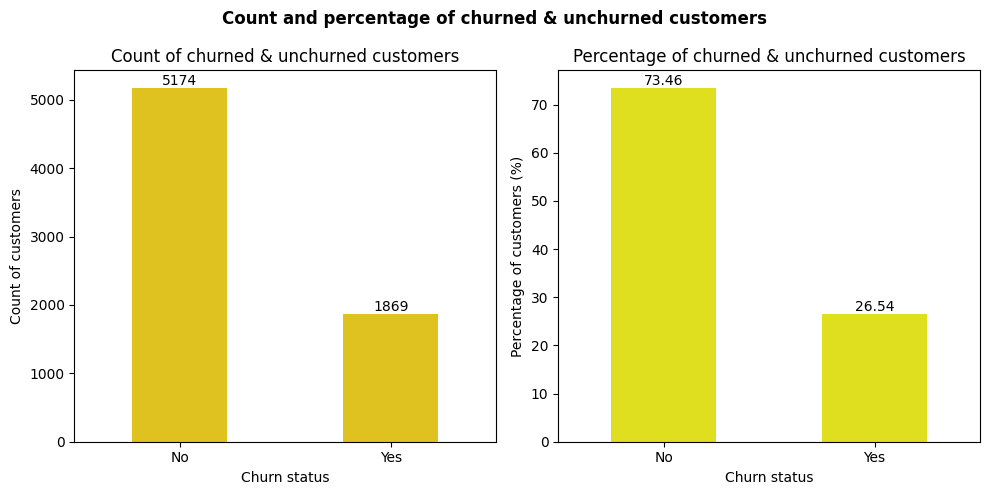

In [64]:
f,ax=plt.subplots(1,2,figsize=(10,5))
seaborn.countplot(telecom_customers_churned,x="is_churned",width=0.45,color="gold",ax=ax[0])
seaborn.countplot(telecom_customers_churned,x="is_churned",width=0.5,color="yellow",stat="percent",ax=ax[1])
ax[0].bar_label(ax[0].containers[0])
ax[1].bar_label(ax[1].containers[0],fmt="%.2f")
for _ in range(2):
  ax[_].set_xlabel("Churn status")
ax[0].set_ylabel("Count of customers")
ax[1].set_ylabel("Percentage of customers (%)")
ax[0].set_title("Count of churned & unchurned customers")
ax[1].set_title("Percentage of churned & unchurned customers")
plt.suptitle("Count and percentage of churned & unchurned customers",fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_and_percentage_of_churned_and_unchurned_customers.png")

#### 💡Insights
- The number of churned customers is less than the unchurned customers.

#### **Proportion of total charge by churn status of customers**

In [65]:
fig=px.pie(telecom_customers_churned,names="is_churned",values="total_charge",title="Proportion of total charge by churn status of customers",color_discrete_map=churn_color_status,labels={"is_churned":"Churn status","total_charge":"Total charge (USD)"})
fig.update_layout(title_x=0.5,title_font_color="black")
fig.show()

#### **Churned customer count with tenure upto 2 years**

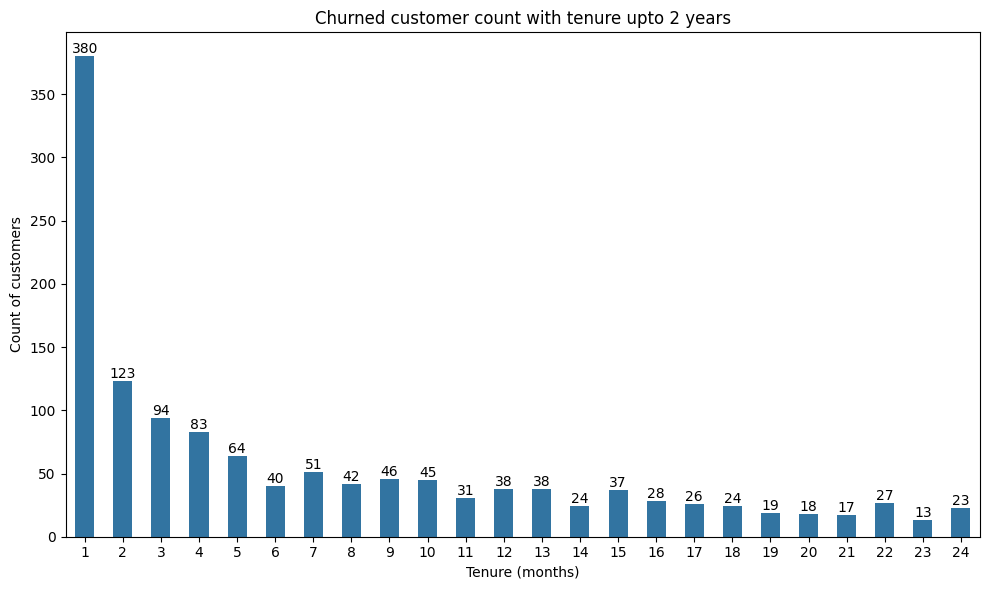

In [66]:
plt.figure(figsize=(10,6))
ax=seaborn.countplot(churned_customers[churned_customers["tenure_in_months"]<=24],x="tenure_in_months",width=0.5)
ax.bar_label(ax.containers[0])
plt.xlabel("Tenure (months)")
plt.ylabel("Count of customers")
plt.title("Churned customer count with tenure upto 2 years")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/churned_customer_count_with_tenure_upto_2_years.png")

#### 💡Insights
- The number of customers churned is higher in 1 month where exactly 380 customers have been churned.
- The second highest tenure in which the customers are churned is in 2 months.
- The number of churning customers decreases drastically after 1.5 years which is after 18 months.

#### **Customer count by total add-on services used**

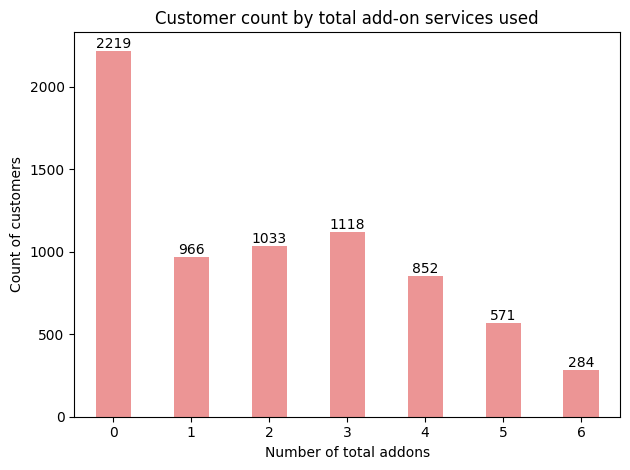

In [67]:
ax=seaborn.countplot(telecom_customers_churned,x="total_addons",color="#fb8686",width=0.45)
ax.bar_label(ax.containers[0])
plt.xlabel("Number of total addons")
plt.ylabel("Count of customers")
plt.title("Customer count by total add-on services used")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/customer_count_by_total_add_on_services_used.png")

#### 💡Insights
- Most of the customers have no add-on services.
- Only 284 customers have all the 6 add-on services.

#### **Distribution of monthly telecom charge of all customers**

In [68]:
fig=px.histogram(telecom_customers_churned,x="monthly_charge",color_discrete_sequence=["blue"],marginal="box",title="Distribution of monthly telecom charge of all customers",labels={"monthly_charge":"Monthly charge"})
fig.update_layout(title_x=0.5,title_font_color="black",xaxis_title="Monthly charge (USD)",yaxis_title="Count of customers")
fig.show()

#### 💡Insights
- Most of the customers have less than 20 USD as their monthly telecom charge.
- Less than 10 customers have monthly charge of around 120 USD.
- Next to 20 USD, more than 300 customers have a monthly telecom charge between 24 and 26 USD.
- The number of customers who paid bills more than 74 USD are gradually reduced.

#### **Distribution of total charges of all customers**

In [69]:
fig=px.histogram(telecom_customers_churned,x="total_charge",marginal="box",color_discrete_sequence=["#A855F7"],title="Distribution of total charges of all customers")
fig.update_layout(title_x=0.5,title_font_color="black",xaxis_title="Total charge (USD)",yaxis_title="Count of customers")
fig.show()

##### 💡Insights
- Most of the customers have paid a total of around 200 USD as telecom charge totally in their tenure.
- The number of customers paying more than 200 USD have gradually reduced.

#### **Customer count by Internet service type**

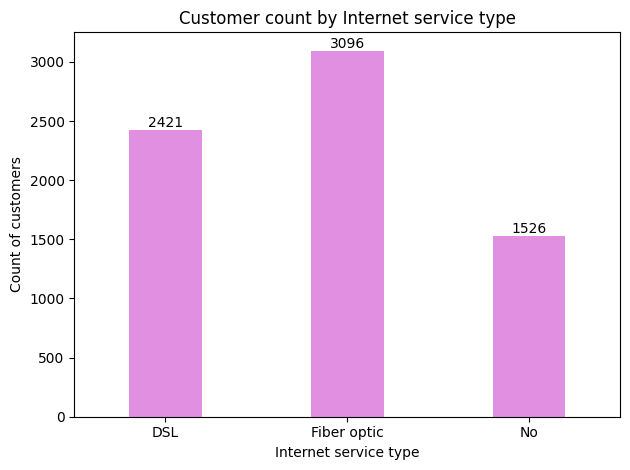

In [70]:
ax=seaborn.countplot(telecom_customers_churned,x="internet_service",width=0.4,color="violet")
ax.bar_label(ax.containers[0])
plt.ylabel("Count of customers")
plt.xlabel("Internet service type")
plt.title("Customer count by Internet service type")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/customer_count_by_internet_service_type.png")

#### 💡Insights
- Most of the customers use fiber optic technology for Internet service.
- DSL technology is the second most preferred Internet service type by the telecom customers.
- 1526 customers did not have Internet service.

#### **Count of customers by payment method**

In [71]:
fig=px.bar(x=telecom_customers_churned["payment_method"].value_counts().index,y=telecom_customers_churned["payment_method"].value_counts().values,title="Count of customers by payment method",labels={"x":"Payment method","y":"Count of customers"},text_auto=True)
fig.update_layout(title_x=0.5,title_font_color="black",xaxis_title="Payment method",yaxis_title="Count of customers")
fig.show()

#### 💡Insights
- Most of the customers use electronic check (e-Check) for payment followed by mailed check.
- Automatic payment for the telecom service is preferred by around 3066 customers.

### **Proportion of total charge paid by customers based on payment methods**

In [72]:
fig=px.pie(telecom_customers_churned,names="payment_method",values="total_charge",title="Proportion of total charge paid by customers based on payment methods")
fig.update_layout(title_x=0.5,title_font_color="black")
fig.show()

#### 💡Insights
- The total charge paid by customers are higher through Electronic check payment method.
- Automatic bank transfer is the second payment method with highest total charge paid by customers, even though automatic bank transfers are done by less than 1600 customers.
- Mailed check payment method generated only 10% of the total charge for the overall telecom services by all customers.

#### **Count of customers by telecom contract type**

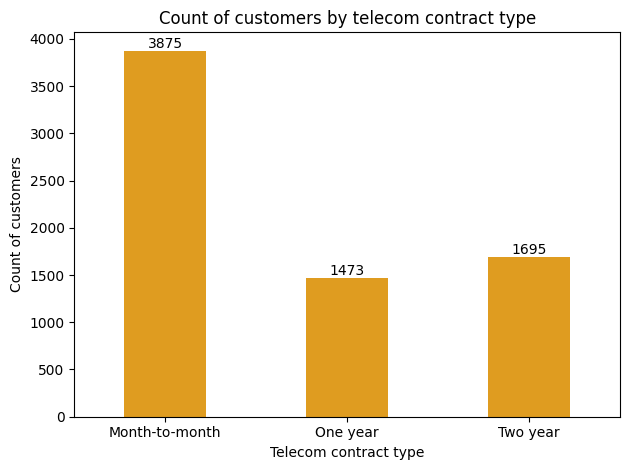

In [73]:
ax=seaborn.countplot(telecom_customers_churned,x="contract_type",width=0.45,color="orange")
ax.bar_label(ax.containers[0])
plt.xlabel("Telecom contract type")
plt.ylabel("Count of customers")
plt.title("Count of customers by telecom contract type")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_of_customers_by_telecom_contract_type.png")

#### 💡Insights
- More than 3500 customers are using month-to-month contract type in the telecom.

#### **Count of telecom customers by tenure type**

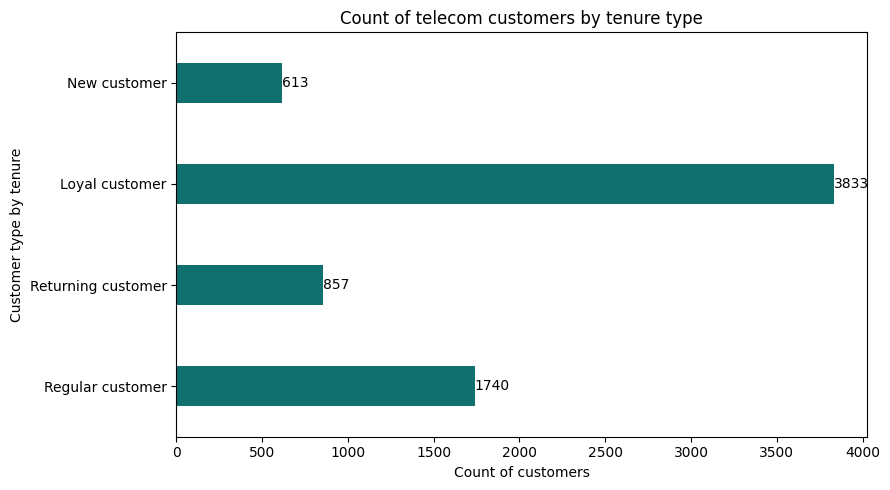

In [74]:
f,ax = plt.subplots(figsize=(9,5))
seaborn.countplot(telecom_customers_churned,y="customer_type_by_tenure",width=0.4,color="teal",ax=ax)
ax.bar_label(ax.containers[0])
plt.ylabel("Customer type by tenure")
plt.xlabel("Count of customers")
plt.title("Count of telecom customers by tenure type")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_of_telecom_customers_by_tenure_type.png")

#### 💡Insights
- Most of the customers are loyal customers with maximum tenure of more than 3 years.

#### **Customer count by family status**

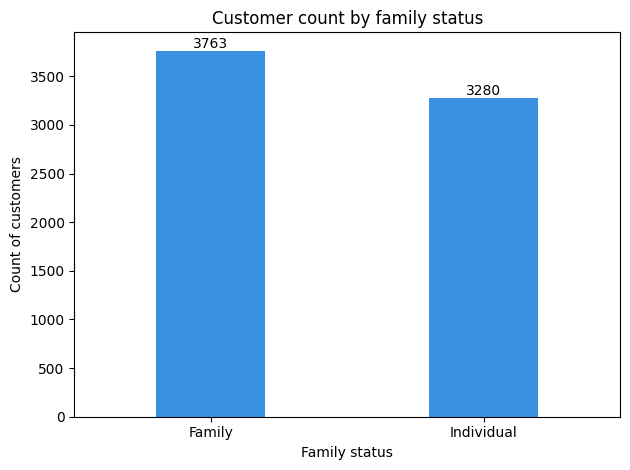

In [75]:
ax=seaborn.countplot(telecom_customers_churned,x="family_status",width=0.4,color="dodgerblue")
ax.bar_label(ax.containers[0])
plt.xlabel("Family status")
plt.ylabel("Count of customers")
plt.title("Customer count by family status")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/customer_count_by_family_status.png")

#### 💡Insights
- Most of the customers are family based customers with dependents or partner.
- The number of individual customers using the telecom service are almost near to the number of family based customers which denotes that the number of individual customers may overtake the number of family customers.

#### **Count of senior citizens & other customers using telecom service**

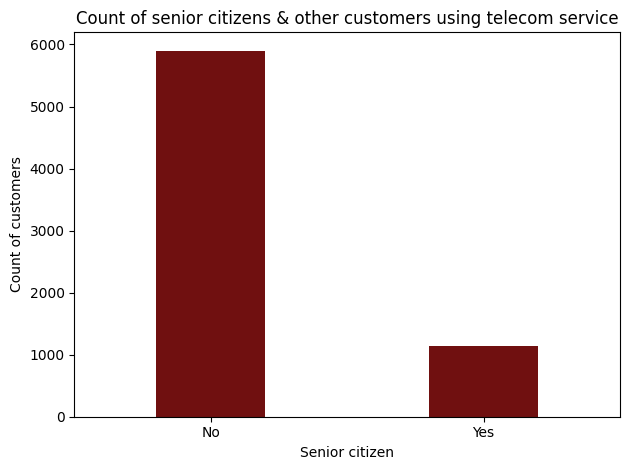

In [76]:
seaborn.countplot(telecom_customers_churned,x="senior_citizen",width=0.4,color="maroon")
plt.xlabel("Senior citizen")
plt.ylabel("Count of customers")
plt.title("Count of senior citizens & other customers using telecom service")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_of_senior_citizens_and_other_customers_using_telecom_service.png")

#### 💡Insights
- More than 5600 customers are not senior citizens.
- Less than 1000 customers are senior citizens.

## **📈Bivariate Analysis**

#### **Tenure vs Total charge**

In [77]:
fig=px.scatter(telecom_customers_churned,x="tenure_in_months",y="total_charge",title="Tenure vs Total charge")
fig.update_layout(title_x=0.5,title_font_color="black",xaxis_title="Tenure (months)",yaxis_title="Total charge (USD)")
fig.show()

#### 💡Insights
- The total charge paid by the customers increases with the tenure.

#### **Average tenure of customers by the total number of add-on services**

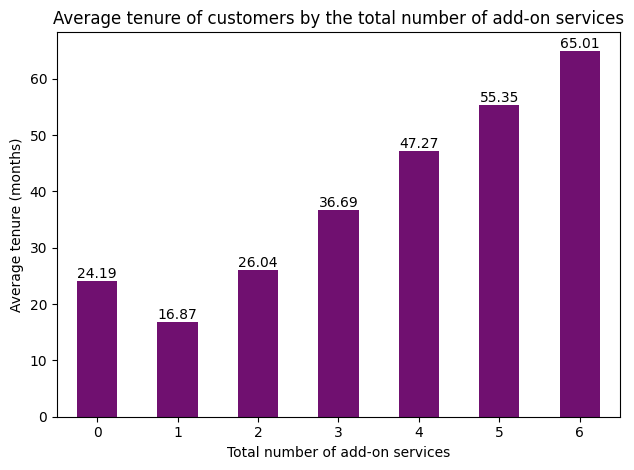

In [78]:
ax=seaborn.barplot(telecom_customers_churned,x="total_addons",y="tenure_in_months",errorbar=None,width=0.5,color="purple")
ax.bar_label(ax.containers[0],fmt="%.2f")
plt.xlabel("Total number of add-on services")
plt.ylabel("Average tenure (months)")
plt.title("Average tenure of customers by the total number of add-on services")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/average_tenure_of_customers_by_the_total_number_of_add_on_services.png")

#### 💡Insights
- The average tenure of the customers with 1 or no add-on service is 2 or less than 2 years.
- The average tenure of the customers using all the 6 add-on services is higher to more than 65 months which is approximately 5.4 years

#### **Total tenure in years by Internet service type**

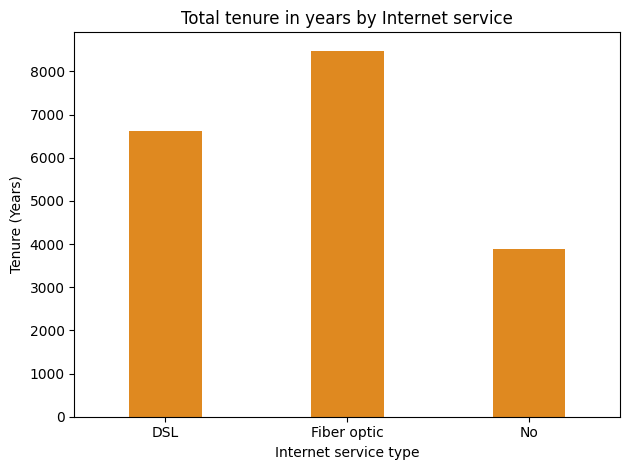

In [79]:
seaborn.barplot(telecom_customers_churned,x="internet_service",y="tenure_in_years",errorbar=None,estimator="sum",width=0.4,color="darkorange")
plt.xlabel("Internet service type")
plt.ylabel("Tenure (Years)")
plt.title("Total tenure in years by Internet service")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/total_tenure_in_years_by_internet_service.png")

#### 💡Insights
- Fiber optic technology is preferred by most of the customers between 1 month to 6 years of tenure followed by DSL.

#### **Count of churned & unchurned customers by total number of add-on services**

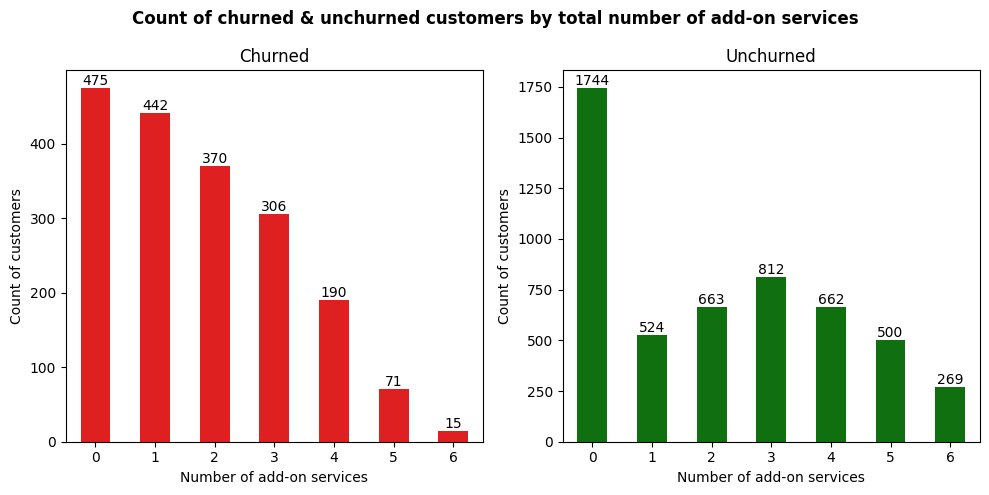

In [80]:
f,ax=plt.subplots(1,2,figsize=(10,5))
seaborn.countplot(churned_customers,x="total_addons",ax=ax[0],color="red",width=0.5)
seaborn.countplot(telecom_customers_churned[telecom_customers_churned["is_churned"]=="No"],x="total_addons",ax=ax[1],color="green",width=0.5)
ax[0].bar_label(ax[0].containers[0])
ax[1].bar_label(ax[1].containers[0])
ax[0].set_title("Churned")
ax[1].set_title("Unchurned")
for _ in range(2):
  ax[_].set_xlabel("Number of add-on services")
  ax[_].set_ylabel("Count of customers")
plt.suptitle("Count of churned & unchurned customers by total number of add-on services",fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_of_churned_and_unchurned_customers_by_total_number_of_addon_services.png")

#### 💡Insights
- The number of churned customers drops significantly with the total number of add-on services used.
- Most of the retained customers are having no add-on services.
- The number of retained customers are higher with those having 3 add-on services instead of no or 1 add-on services.

#### **Comparison of count of churned customers in 1 & 2 months by various telecom services**

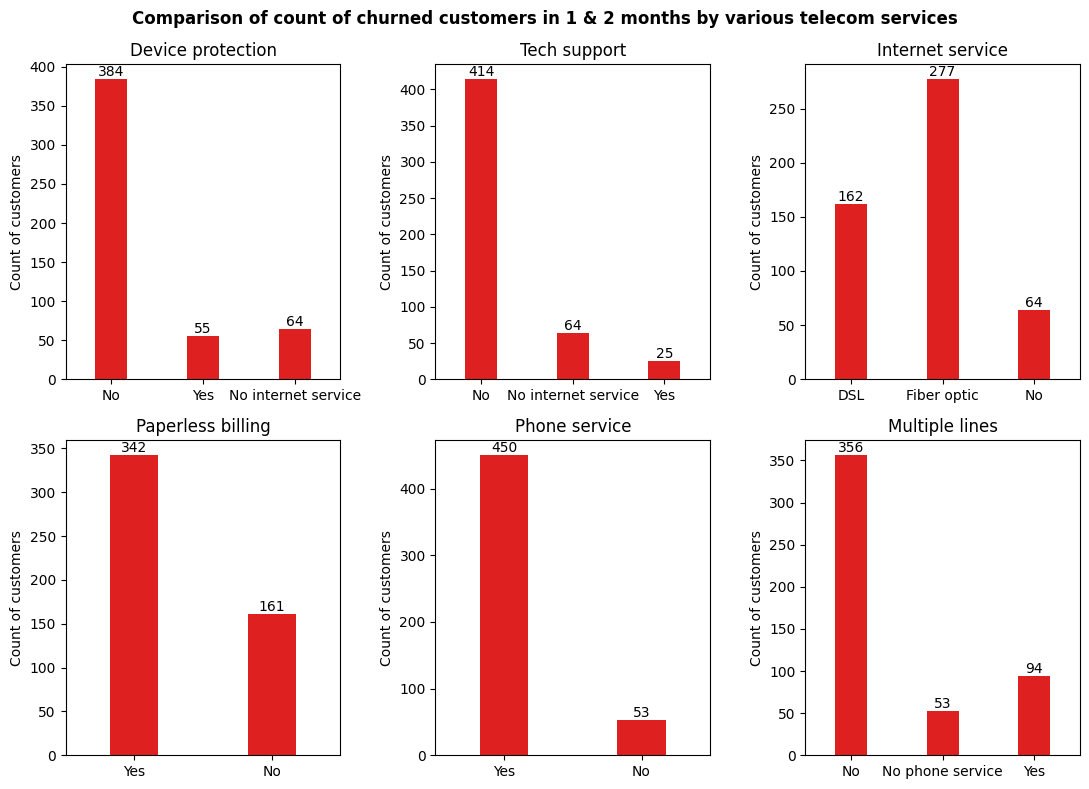

In [81]:
top_churned_customers = churned_customers[(churned_customers["tenure_in_months"]==1)|(churned_customers["tenure_in_months"]==2)]
f,ax=plt.subplots(2,3,figsize=(11,8))
seaborn.countplot(top_churned_customers,x="has_device_protection",ax=ax[0,0],width=0.35,color="red")
seaborn.countplot(top_churned_customers,x="has_tech_support",ax=ax[0,1],width=0.35,color="red")
seaborn.countplot(top_churned_customers,x="internet_service",ax=ax[0,2],width=0.35,color="red")
seaborn.countplot(top_churned_customers,x="has_paperless_billing",ax=ax[1,0],width=0.35,color="red")
seaborn.countplot(top_churned_customers,x="phone_service",ax=ax[1,1],width=0.35,color="red")
seaborn.countplot(top_churned_customers,x="multiple_lines",ax=ax[1,2],width=0.35,color="red")
services_list = ["Device protection","Tech support","Internet service","Paperless billing","Phone service","Multiple lines"]
ptr = 0
for rowIndex in range(2):
  for colIndex in range(3):
    ax[rowIndex,colIndex].set_title(services_list[ptr])
    ax[rowIndex,colIndex].set_ylabel("Count of customers")
    ax[rowIndex,colIndex].set(xlabel=None)
    ax[rowIndex,colIndex].bar_label(ax[rowIndex,colIndex].containers[0])
    ptr += 1
plt.suptitle("Comparison of count of churned customers in 1 & 2 months by various telecom services",fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/comparison_of_count_of_churned_customers_in_1_and_2_months_by_various_telecom_services.png")

#### 💡Insights
- Most of the churned customers in 1 or 2 months lacks device protection and tech support.
- Most of the customers churned in 1 or 2 months had phone service, but not multiple lines.
- Fiber optic Internet service is used by these top churned customers.

#### **Average tenure of churned customers by family status**

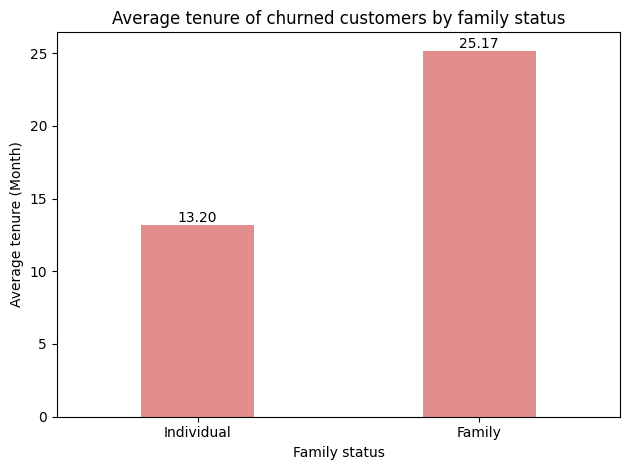

In [82]:
ax=seaborn.barplot(churned_customers,x="family_status",y="tenure_in_months",errorbar=None,width=0.4,color="lightcoral")
ax.bar_label(ax.containers[0],fmt="%.2f")
plt.xlabel("Family status")
plt.ylabel("Average tenure (Month)")
plt.title("Average tenure of churned customers by family status")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/average_tenure_of_churned_customers_by_family_status.png")

#### 💡Insights
- The average tenure of churned customers with partner or dependents are longer than 1.5 years which is higher than individuals.

## **📈Multivariate Analysis**

#### **Correlation Heatmap**

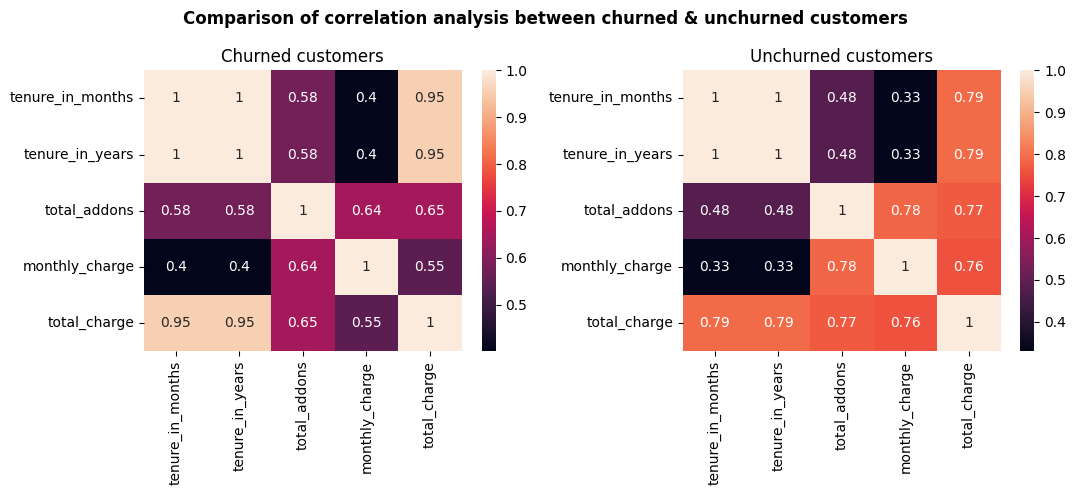

In [83]:
f,ax=plt.subplots(1,2,figsize=(11,5))
seaborn.heatmap(churned_customers.corr(numeric_only=True),annot=True,ax=ax[0])
seaborn.heatmap(telecom_customers_churned[telecom_customers_churned["is_churned"]=="No"].corr(numeric_only=True),annot=True,ax=ax[1])
ax[0].set_title("Churned customers")
ax[1].set_title("Unchurned customers")
plt.suptitle("Comparison of correlation analysis between churned & unchurned customers",fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/correlation_heatmap.png")

#### 💡Insights
- There is strong positive correlation between the tenure and total charge of churned customers indicating that the revenue from the churned customers was higher.
- Moderate positive correlation exists between the tenure and total charge of unchurned customers which indicates that the revenue from more than half of the loyal customers can be increased by providing more add-ons & telecom services for their longest tenure.
- A moderate correlation exists between the total number of add-on services and the total charge of unchurned customers which is higher than the moderate correlation in churned customers.

#### **Count of churned & unchurned customers by payment method**

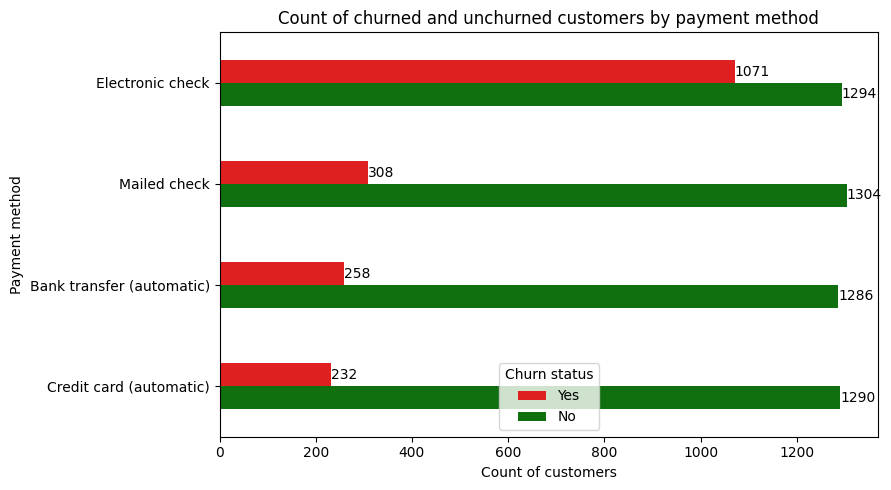

In [84]:
f,ax=plt.subplots(figsize=(9,5))
seaborn.countplot(telecom_customers_churned,y="payment_method",hue="is_churned",hue_order=["Yes","No"],ax=ax,width=0.45,palette=churn_color_status)
for container in ax.containers:
  ax.bar_label(container)
plt.ylabel("Payment method")
plt.xlabel("Count of customers")
plt.title("Count of churned and unchurned customers by payment method")
plt.legend(title="Churn status")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_of_churned_and_unchurned_customers_by_payment_method.png")

#### 💡Insights
- Most of the churned customers have used electronic check as payment method followed by mailed check.
- Automatic bank transfer is preferred by less than 240 churned customers.

#### **Customer count by Internet service type & churn status**

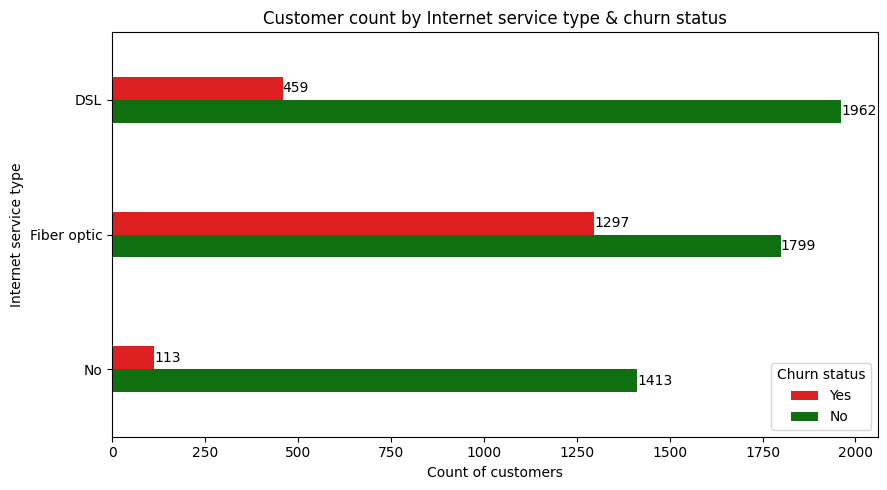

In [85]:
plt.figure(figsize=(9,5))
ax=seaborn.countplot(telecom_customers_churned,y="internet_service",width=0.34,hue="is_churned",hue_order=["Yes","No"],palette=churn_color_status)
plt.xlabel("Count of customers")
plt.ylabel("Internet service type")
plt.title("Customer count by Internet service type & churn status")
for container in ax.containers:
  ax.bar_label(container)
plt.legend(title="Churn status")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/customer_count_by_internet_service_type_and_churn_status.png")

#### **Average tenure of churned & unchurned customers by payment method**

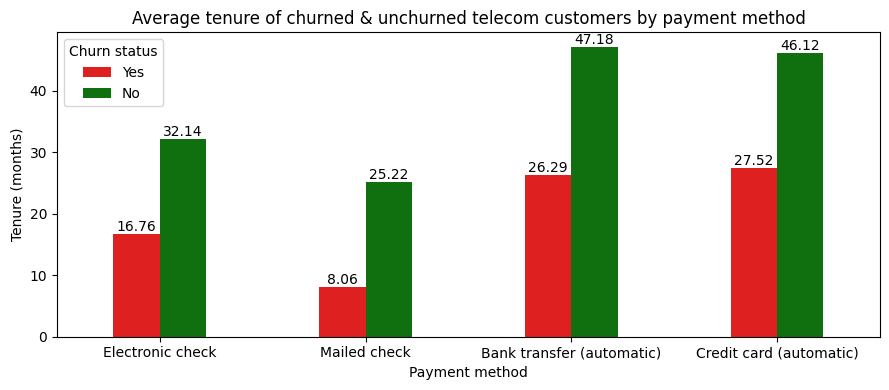

In [86]:
plt.figure(figsize=(9,4))
ax=seaborn.barplot(telecom_customers_churned,x="payment_method",y="tenure_in_months",hue="is_churned",hue_order=["Yes","No"],width=0.45,errorbar=None,palette=churn_color_status)
for container in ax.containers:
  ax.bar_label(container,fmt='%.2f')
plt.xlabel("Payment method")
plt.ylabel("Tenure (months)")
plt.title("Average tenure of churned & unchurned telecom customers by payment method")
plt.legend(title="Churn status")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/average_tenure_of_churned_and_unchurned_telecom_customers_by_payment_method.png")

#### 💡Insights
- The average tenure in months was higher with the churned customers who used automatic transfers.
- The average tenure is very low for the churned customers who used mailed check as payment method which is less than 10 months.
- The average tenure of churned customers who used electronic check as payment method is less than 1.5 years.

#### **Average tenure of telecom customers by number of add-on services**

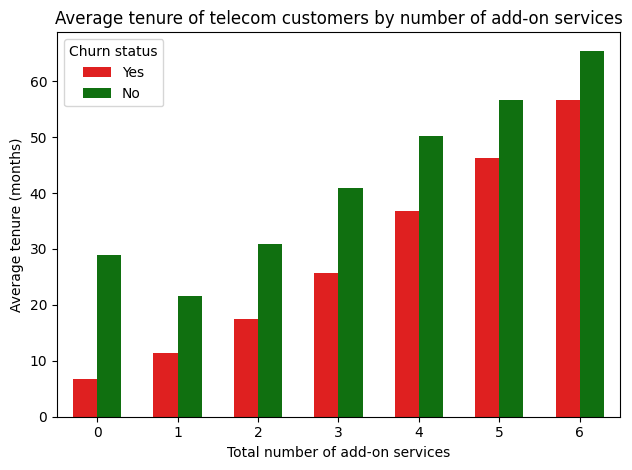

In [87]:
seaborn.barplot(telecom_customers_churned,x="total_addons",y="tenure_in_months",hue="is_churned",errorbar=None,width=0.6,palette=churn_color_status)
plt.xlabel("Total number of add-on services")
plt.ylabel("Average tenure (months)")
plt.title("Average tenure of telecom customers by number of add-on services")
plt.legend(title="Churn status")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/average_tenure_of_telecom_customers_by_number_of_addon_services.png")

#### 💡Insights
- The average tenure of churned customers is less than 10 months for the customers with no add-on services.
- The highest average tenure of churned customers is with the customers with all 6 add-on services which is more than 60 months (5 years).
- The average tenure of churned customers gets higher with the total number of add-on services used.

#### **Tenure vs Monthly telecom charge of churned & unchurned customers**

In [88]:
fig=px.scatter(telecom_customers_churned.sort_values(by=["tenure_in_months"]),x="tenure_in_months",y="monthly_charge",color="is_churned",color_discrete_map=churn_color_status,title="Tenure vs Monthly telecom charge of churned & unchurned customers",labels={"monthly_charge":"Monthly charge (USD)","tenure_in_months":"Tenure (months)","is_churned":"Churn status"})
fig.update_layout(title_x=0.5,title_font_color="black",xaxis_title="Tenure (months)",yaxis_title="Monthly charge (USD)")
fig.show()

#### 💡Insights
- Most of the churned customers with less than 6 months of tenure had total charge between 20 to 105 USD.
- Most of the tenure of the churned customers with monthly charge between 20 to 80 USD did not exceed 10 to 12 months.
- Most of the churned customers with more than 50 months tenure had monthly charge above 80 USD.

#### **Tenure vs Total charge of churned customers by gender**

In [89]:
fig=px.scatter(telecom_customers_churned[telecom_customers_churned["is_churned"]=="Yes"].sort_values(by=["tenure_in_months"]),x="tenure_in_months",y="total_charge",color="gender",color_discrete_map={"Male":"deepskyblue","Female":"deeppink"},title="Tenure vs Total charge of churned customers by gender",labels={"total_charge":"Total charge (USD)","tenure_in_months":"Tenure (months)","is_churned":"Churn status"})
fig.update_layout(title_x=0.5,title_font_color="black",xaxis_title="Tenure (months)",yaxis_title="Total charge (USD)",legend_title_text="Gender")
fig.show()

#### 💡Insights
- The number of churned customers with less than 30 months (2.5 years) is almost the same for males and females with total charge around 4000 USD.
- Both male and female churned customers are less in number after 50 months which is approximately 4.2 years.

#### **Average tenure of telecom contract types by churned & unchurned customers**

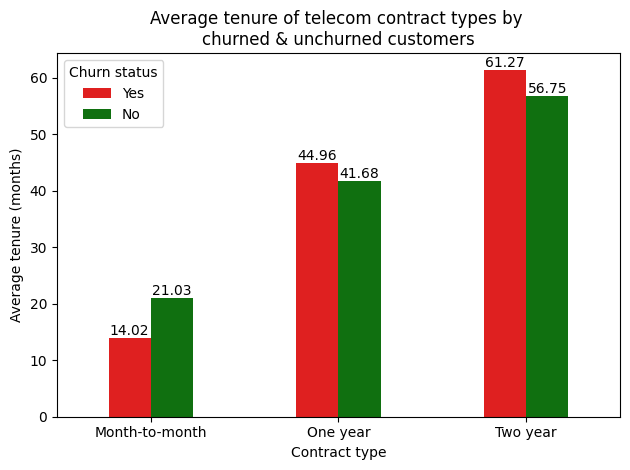

In [90]:
ax=seaborn.barplot(telecom_customers_churned,x="contract_type",y="tenure_in_months",hue="is_churned",hue_order=["Yes","No"],errorbar=None,width=0.45,palette=churn_color_status)
for container in ax.containers:
  ax.bar_label(container,fmt="%.2f")
plt.xlabel("Contract type")
plt.ylabel("Average tenure (months)")
plt.title("Average tenure of telecom contract types by \nchurned & unchurned customers")
plt.legend(title="Churn status")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/average_tenure_of_telecom_contract_types_by_churned_and_unchurned_customers.png")

#### 💡Insights
- The average tenure of churned customers is less for the customers who opted for month-to-month contract which is 1 year.
- The average tenure of the churned customers with 2-year contract had the longest tenure of more than 5 years.

#### **Average tenure of churned & unchurned customers by Internet service type**

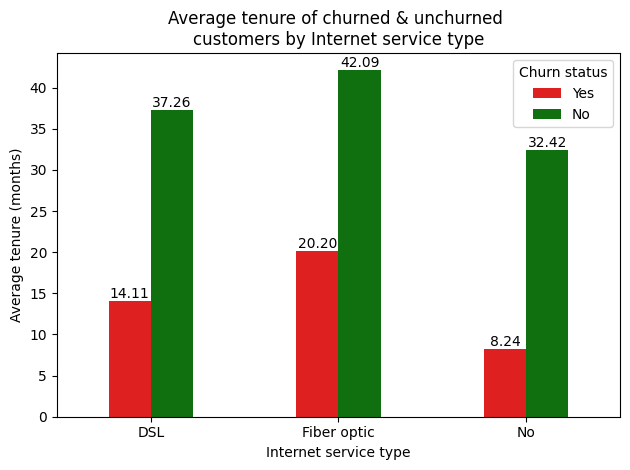

In [91]:
ax=seaborn.barplot(telecom_customers_churned,x="internet_service",y="tenure_in_months",hue="is_churned",hue_order=["Yes","No"],errorbar=None,palette=churn_color_status,width=0.45)
for container in ax.containers:
  ax.bar_label(container,fmt='%.2f')
plt.xlabel("Internet service type")
plt.ylabel("Average tenure (months)")
plt.title("Average tenure of churned & unchurned \ncustomers by Internet service type")
plt.legend(title="Churn status")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/average_tenure_of_churned_and_unchurned_customers_by_internet_service_type.png")

#### 💡Insights
- The average tenure of the churned customers with DSL technology had less tenure of 1.2 years compared to the customers who used fiber optic technology.
- The average tenure of the churned customers with no Internet service had less than 6 months of tenure which is very less compared to the average tenure of customers who used Internet.

#### **Count of churned & unchurned customers by age group**

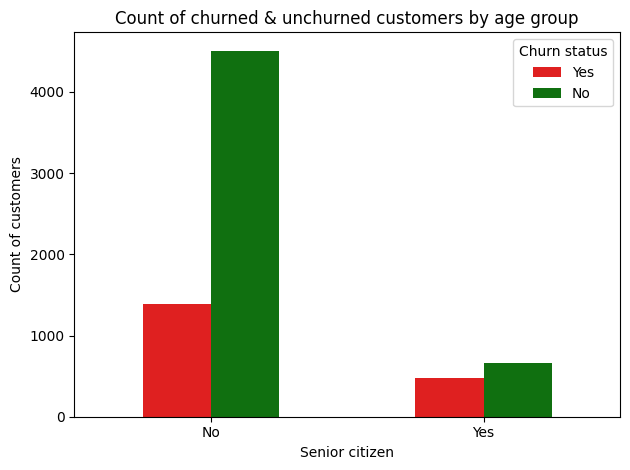

In [92]:
seaborn.countplot(telecom_customers_churned,x="senior_citizen",hue="is_churned",hue_order=["Yes","No"],palette=churn_color_status,width=0.5)
plt.xlabel("Senior citizen")
plt.ylabel("Count of customers")
plt.legend(title="Churn status")
plt.title("Count of churned & unchurned customers by age group")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_of_churned_and_unchurned_customers_by_age_group.png")

#### 💡Insights
- More than 1100 churned customers are not senior citizens, whereas around 500 customers who churned are senior citizens.

#### **Comparison of count of churned & unchurned customers with phone service and multiple lines**

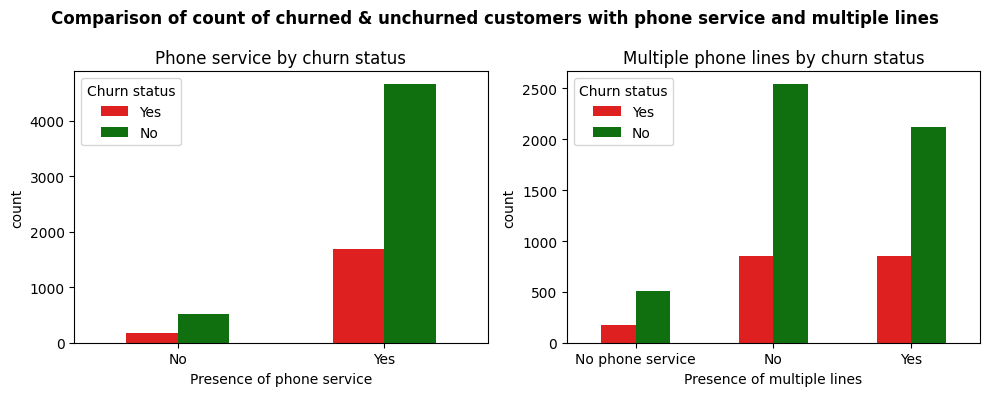

In [93]:
f,ax=plt.subplots(1,2,figsize=(10,4))
seaborn.countplot(telecom_customers_churned,x="phone_service",hue="is_churned",hue_order=["Yes","No"],ax=ax[0],palette=churn_color_status,width=0.5)
seaborn.countplot(telecom_customers_churned,x="multiple_lines",hue="is_churned",hue_order=["Yes","No"],ax=ax[1],palette=churn_color_status,width=0.5)
ax[0].set_title("Phone service by churn status")
ax[0].set_xlabel("Presence of phone service")
ax[0].legend(title="Churn status")
ax[1].set_title("Multiple phone lines by churn status")
ax[1].set_xlabel("Presence of multiple lines")
ax[1].legend(title="Churn status")
plt.suptitle("Comparison of count of churned & unchurned customers with phone service and multiple lines",fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/comparison_of_count_of_churned_and_unchurned_customers_with_phone_service_and_multiple_lines.png")

#### 💡Insights
- Most of the churned customers had phone service.
- The number of churned customers with and without multiple lines are almost the same.

#### **Count of customers using various add-on services by churn status**

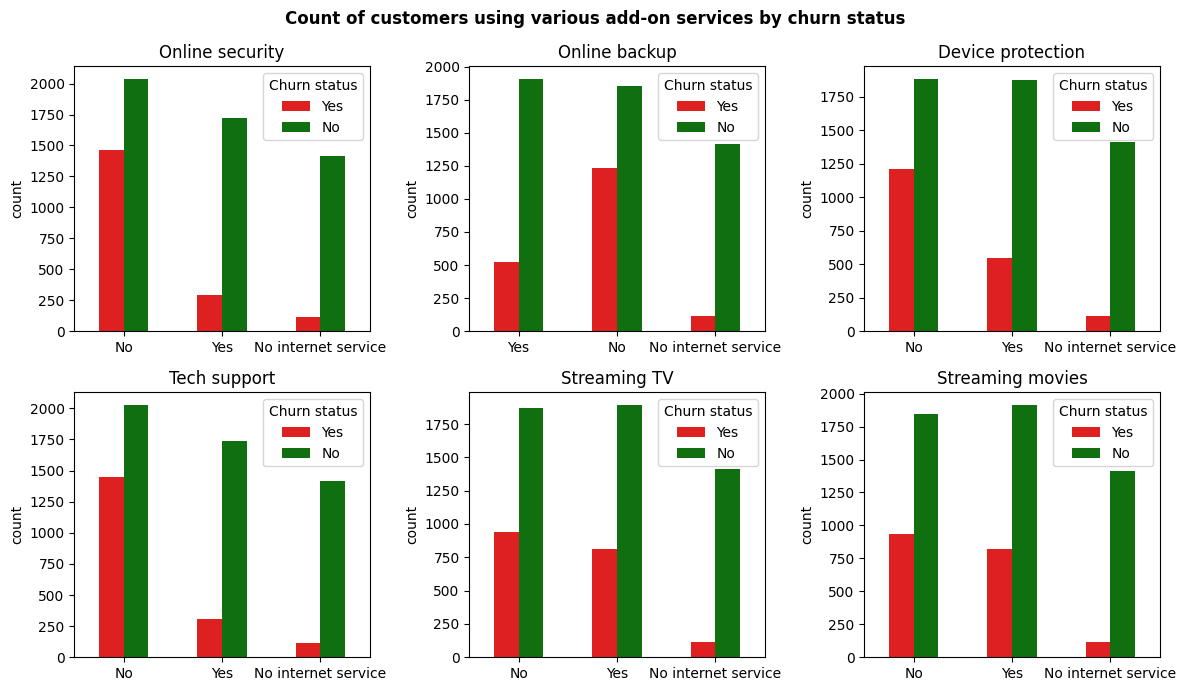

In [94]:
f,ax=plt.subplots(2,3,figsize=(12,7))
seaborn.countplot(telecom_customers_churned,x="has_online_security",hue="is_churned",hue_order=["Yes","No"],ax=ax[0,0],palette=churn_color_status,width=0.5)
seaborn.countplot(telecom_customers_churned,x="has_online_backup",hue="is_churned",hue_order=["Yes","No"],ax=ax[0,1],palette=churn_color_status,width=0.5)
seaborn.countplot(telecom_customers_churned,x="has_device_protection",hue="is_churned",hue_order=["Yes","No"],ax=ax[0,2],palette=churn_color_status,width=0.5)
seaborn.countplot(telecom_customers_churned,x="has_tech_support",hue="is_churned",hue_order=["Yes","No"],ax=ax[1,0],palette=churn_color_status,width=0.5)
seaborn.countplot(telecom_customers_churned,x="has_streaming_tv",hue="is_churned",hue_order=["Yes","No"],ax=ax[1,1],palette=churn_color_status,width=0.5)
seaborn.countplot(telecom_customers_churned,x="has_streaming_movies",hue="is_churned",hue_order=["Yes","No"],ax=ax[1,2],palette=churn_color_status,width=0.5)
add_on_list = ["Online security","Online backup","Device protection","Tech support","Streaming TV","Streaming movies"]
list_ptr = 0
for rowIndex in range(0,2):
  for colIndex in range(0,3):
    ax[rowIndex,colIndex].legend(title="Churn status")
    ax[rowIndex,colIndex].set_title(add_on_list[list_ptr])
    ax[rowIndex,colIndex].set(xlabel=None)
    list_ptr += 1
plt.suptitle("Count of customers using various add-on services by churn status",fontweight="bold")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_of_customers_using_various_addon_services_by_churn_status.png")

#### 💡Insights
- The number of churning is high with customers with no online security, no online backup, no device protection, no tech support, no streaming TV and movies.

#### **Count of customers by Internet service type & customer type by tenure**

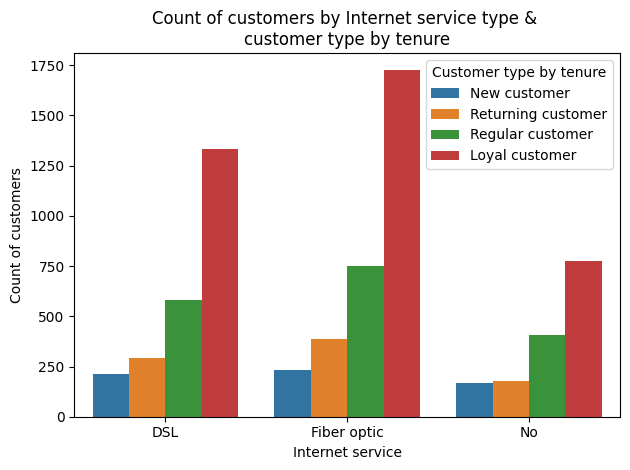

In [95]:
seaborn.countplot(telecom_customers_churned,x="internet_service",hue="customer_type_by_tenure",hue_order=["New customer","Returning customer","Regular customer","Loyal customer"])
plt.xlabel("Internet service")
plt.ylabel("Count of customers")
plt.legend(title="Customer type by tenure")
plt.title("Count of customers by Internet service type & \ncustomer type by tenure")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_of_customers_by_internet_service_type_and_customer_type_by_tenure.png")

#### 💡Insights
- The number of loyal customers using fiber optic technology is higher to around 1600 than the DSL technology for Internet.

#### **Customer count by usage of entertainment add-ons between churned & unchurned**

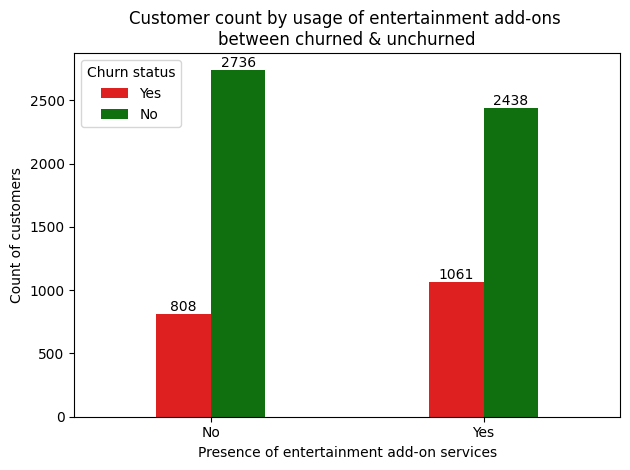

In [96]:
ax=seaborn.countplot(telecom_customers_churned,x="entertainment_service",hue="is_churned",hue_order=["Yes","No"],palette=churn_color_status,width=0.4)
for container in ax.containers:
  ax.bar_label(container)
plt.xlabel("Presence of entertainment add-on services")
plt.ylabel("Count of customers")
plt.title("Customer count by usage of entertainment add-ons \nbetween churned & unchurned")
plt.legend(title="Churn status")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/customer_count_by_usage_of_entertainment_add_ons_between_churned_and_unchurned.png")

#### 💡Insights
- The number of customers using entertainment add-on services are churned mostly than the churned with no entertainment add-on services.

#### **Distribution of monthly charge of churned customers by Internet service type**

In [97]:
fig=px.histogram(churned_customers,x="monthly_charge",nbins=80,color="internet_service",title="Distribution of monthly charge of churned customers by Internet service type",color_discrete_map={"DSL":"blue","Fiber optic":"darkred","No":"lime"})
fig.update_layout(title_x=0.5,title_font_color="black",xaxis_title="Monthly charge (USD)",yaxis_title="Count of customers",legend_title_text="Internet service type")
fig.show()

#### 💡Insights
- The number of churned customers is higher with those whose monthly charge is above 70 USD.
- Churning is high with customers using fiber optic technology for Internet.
- Churning is high with DSL customers whose monthly charge is between 45 to 55 USD.

#### **Count of top churned customers by family status & number of add-on services**

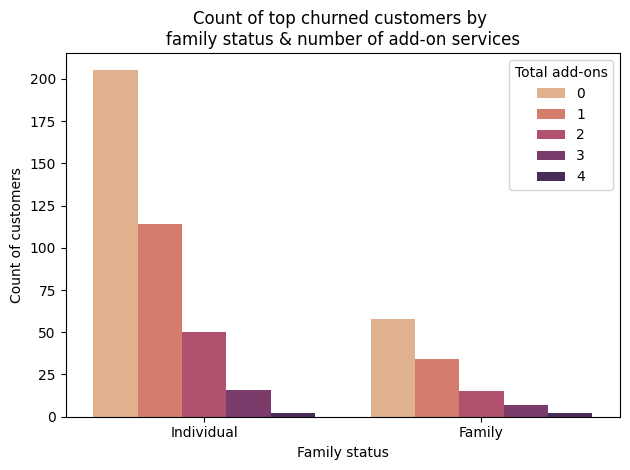

In [98]:
seaborn.countplot(top_churned_customers,x="family_status",hue="total_addons",palette="flare")
plt.xlabel("Family status")
plt.ylabel("Count of customers")
plt.title("Count of top churned customers by \nfamily status & number of add-on services")
plt.legend(title="Total add-ons")
plt.tight_layout()
plt.savefig("/kaggle/working/plots/count_of_top_churned_customers_by_family_status_and_number_of_addon_services.png")

#### 💡Insights
- Churning is high with individual customers having 0 add-ons than family customers.

# **⭐Key Insights**

#### **📡Telecom customers**
- Churned - 1869 (26.54%)
- Unchurned - 5174 (73.46%)

#### **📲Phone service of churned customers**
- Using phone service - ~ 1700
- Without phone service - ~ 100

#### **🛜Internet service of churned customers**
1. Fiber optic - 1297 customers
2. DSL - 459 customers
3. No Internet - 113 customers

#### **🧩Add-on services**
- Churning is high with no online security
- Churning is high with no online backup
- Churning is high with no device protection
- Churning is high with no tech support
- Churning is high with no streaming TV & movies

#### **❇️Number of add-ons of churned customers**
- 0 add-ons - 475 customers
- 1 add-on - 442 customers
- 2 add-ons - 370 customers
- 3 add-ons - 306 customers
- 4 add-ons - 190 customers
- 5 add-ons - 71 customers
- 6 add-ons - 15 customers

#### **💳Payment methods ranked by churn count**
1.   Electronic check - 1071 customers
2.   Mailed check - 308 customers
3.   Bank transfer (automatic) - 258 customers
4.   Credit card (automatic) - 232 customers

#### **👤Age group**
- People less than 60 years old have churned more than senior citizens.

#### **🗓️Top tenures with maximum churning**
- Churning is high in less than 6 months tenure
- 1 month - 380 customers
- 2 months - 123 customers
- 3 months - 94 customers

#### **💵Monthly charge**
- Minimum monthly charge: 18.25 USD
- Maximum monthly charge: 118.75 USD
- Churning is high when monthly charge exceeds 65 USD


### **⬆️Ranking churning by Average tenure**
#### **📜Contract type**
1. Month-to-month - 14 months
2. One year - 45 months
3. Two year - 61 months

#### **🌐Internet service type**
1. No Internet - 8.2 months
2. DSL - 14 months
3. Fiber optic - 20 months

#### **💳Payment methods**
1. Mailed check - 8 months
2. Electronic check - 16.76 months
3. Automatic (Bank or Credit card) - 46.5 months

#### **👨‍👩‍👧Family status of churned customers**
1. Individuals - 14 months
2. Family - 25 months

#### **➕Total add-on services**
Tenure reduces with increasing number of add-on services.
1. No add-ons - 7 months (0.5 year approximately)
2. 1 add-on - 12 months (1 year approximately)
3. 2 add-ons - 17 months (1.5 years approximately)
4. 5 add-ons - 47 months (3.9 years approximately)
5. 6 add-ons - 55 months (4.5 years approximately)


# **💼Business Recommendations**
  - Provide 1 or 2 free add-ons as welcome offer to new customers for their initial 3 to 6 months to boost customer retention.
  - Offer billing discounts or festive coupons to returning & regular customers spending over 70 USD as monthly charge.
  - Provide high quality connectors, strong physical lines, and high-performance routers to customers using fiber optic technology for Internet service to avoid frequent network issues.
  - Provide 24x7 customer assistance line over the phone to receive customer queries & complaints regarding service disruption and other issues to enhance customer experience. This also helps senior citizens to make complaints easily who lack usage of mobile app.
  - Hire more technicians to repair phone lines, network downtime and Internet downtime.
  - Launch an app to make online complaints easier for customers in addition to the dedicated 24x7 customer assistance phone line.